# code_114 · Learned edge functions, spline baselines and geometry contracts

**Book:** section 22.7. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_22_GUIDE.md), [run evidence](../CHAPTER_22_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_114).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2314;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2314


<a id="function-contract"></a>
 ## Approximation is not a learning guarantee
 Fit a dimensionless smooth response sin(2*x0*x1)+0.4*x0² with observation noise SD0.03. Training500/development160/final300 inputs lie in [-1,1]²; a separate final200 cohort puts x0 in [1.05,1.8]. Compare additive and tensor-product spline/Ridge baselines, a width24 tanh MLP and an original 2→4→1 KAN-style composition of learned univariate edge functions. Cubic basis grids are fixed, not adaptively learned: first-layer range[-1,1], hidden range[-3,3], eleven basis coefficients per edge plus a learned SiLU base and node offsets. This executes the stated edge-function mechanism, not a reproduction of the full KAN paper benchmark. Each family has two declared development candidates and all final cohorts remain locked.


,model,development_MSE,final_source_MSE,final_extrapolation_MSE,parameters,selected_alpha,selected_rate,best_step
0,Additive spline,0.278219,0.312029,0.941847,23,1.00,NaN,NaN
1,Tensor spline,0.001172,0.001081,0.375514,122,0.01,NaN,NaN
2,MLP,0.002049,0.002135,0.260425,97,NaN,0.010,400.0
3,KAN-style,0.001138,0.001071,0.345446,149,NaN,0.005,400.0


,model,rotation_prediction_RMS_difference,final_radial_response_MSE
0,Raw coordinates,3.636891e-02,0.002718
1,Radial feature,7.355637e-17,0.000005


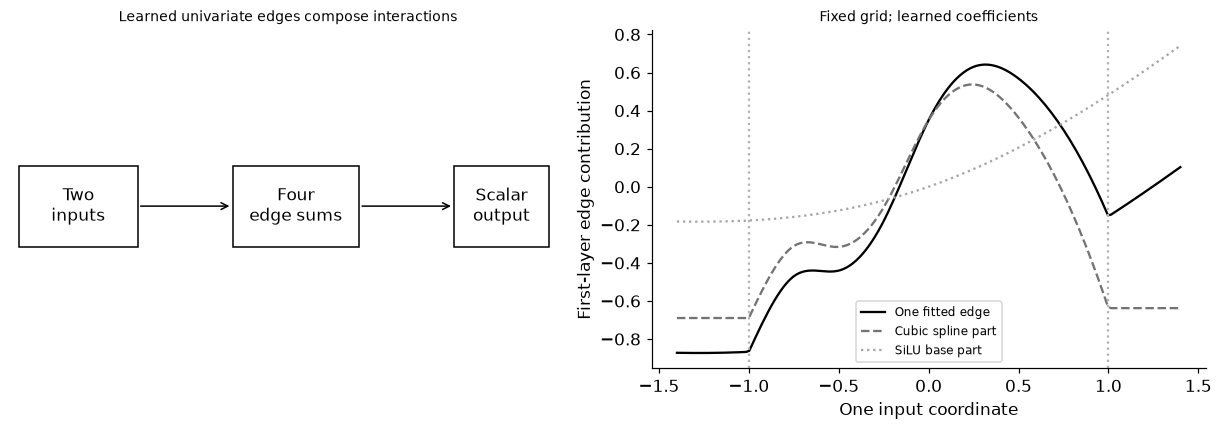

In [2]:
import copy
from scipy.interpolate import BSpline
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import Ridge
def spline_knots(low,high,reference):
    grid=torch.linspace(low,high,9,device=reference.device,dtype=reference.dtype);return torch.cat([grid[:1].repeat(3),grid,grid[-1:].repeat(3)])
def cubic_basis(values,low,high):
    knots=spline_knots(low,high,values);z=values.clamp(low,high);basis=((z[...,None]>=knots[:-1])&(z[...,None]<knots[1:])).to(values.dtype)
    for degree in range(1,4):
        count=len(knots)-degree-1;left=knots[degree:degree+count]-knots[:count];right=knots[degree+1:degree+count+1]-knots[1:count+1];safe_left=torch.where(left>0,left,torch.ones_like(left));safe_right=torch.where(right>0,right,torch.ones_like(right));a=(z[...,None]-knots[:count])/safe_left*(left>0);b=(knots[degree+1:degree+count+1]-z[...,None])/safe_right*(right>0);basis=a*basis[...,:count]+b*basis[...,1:count+1]
    endpoint=values.new_zeros(basis.shape[-1]);endpoint[-1]=1.;return torch.where((z==high)[...,None],endpoint,basis)
# An independent implementation and an interior derivative check audit the spline recurrence.
grid=torch.linspace(-1,1,33)[:,None];basis=cubic_basis(grid,-1,1);knots=spline_knots(-1,1,grid).numpy();reference=BSpline.design_matrix(grid[:,0].numpy(),knots,3,extrapolate=False).toarray();np.testing.assert_allclose(basis[:,0].numpy(),reference,atol=1e-12);torch.testing.assert_close(basis.sum(-1),torch.ones(33,1));assert torch.min(basis)>=0
interior=torch.tensor([[-.17,.23]],requires_grad=True);assert torch.autograd.gradcheck(lambda z:cubic_basis(z,-1,1),(interior,),eps=1e-6,atol=1e-5,rtol=1e-3)
torch.testing.assert_close(cubic_basis(torch.tensor([[1.4]]),-1,1),cubic_basis(torch.tensor([[1.]]),-1,1),atol=0,rtol=0)
class EdgeLayer(nn.Module):
    def __init__(self,incoming,outgoing,low,high):
        super().__init__();self.low=low;self.high=high;self.coefficients=nn.Parameter(torch.randn(outgoing,incoming,11)*.02);self.base=nn.Parameter(torch.randn(outgoing,incoming)*.1);self.bias=nn.Parameter(torch.zeros(outgoing))
    def forward(self,values):return torch.einsum('bin,oin->bo',cubic_basis(values,self.low,self.high),self.coefficients)+nn.functional.silu(values)@self.base.T+self.bias
class EdgeNetwork(nn.Module):
    def __init__(self):super().__init__();self.first=EdgeLayer(2,4,-1,1);self.second=EdgeLayer(4,1,-3,3)
    def forward(self,values):return self.second(self.first(values)).squeeze(-1)
def make_mlp():return nn.Sequential(nn.Linear(2,24),nn.Tanh(),nn.Linear(24,1),nn.Flatten(0))
def response(values):return np.sin(2*values[:,0]*values[:,1])+.4*values[:,0]**2
train=rng.uniform(-1,1,(500,2));dev=rng.uniform(-1,1,(160,2));final=rng.uniform(-1,1,(300,2));outside=np.column_stack([rng.uniform(1.05,1.8,200),rng.uniform(-1,1,200)])
ytrain=response(train)+rng.normal(0,.03,500);ydev=response(dev)+rng.normal(0,.03,160);yfinal=response(final)+rng.normal(0,.03,300);youtside=response(outside)+rng.normal(0,.03,200)
rows=[];candidates=[];fitted={};fixed_knots=np.repeat(np.linspace(-1,1,9)[:,None],2,axis=1);transformer=SplineTransformer(knots=fixed_knots,degree=3,include_bias=True,extrapolation='constant').fit(train);spline_candidates=[]
for alpha in [.01,1.]:
    model=Ridge(alpha=alpha).fit(transformer.transform(train),ytrain);error=float(np.mean((model.predict(transformer.transform(dev))-ydev)**2));spline_candidates.append((error,alpha,model));candidates.append({'model':'Additive spline','alpha':alpha,'development_MSE':error})
best,alpha,model=min(spline_candidates,key=lambda r:r[0]);rows.append({'model':'Additive spline','development_MSE':best,'final_source_MSE':float(np.mean((model.predict(transformer.transform(final))-yfinal)**2)),'final_extrapolation_MSE':float(np.mean((model.predict(transformer.transform(outside))-youtside)**2)),'parameters':len(model.coef_)+1,'selected_alpha':alpha});fitted['Additive spline']=model

# A second spline baseline supplies explicit interactions at a comparable small-data parameter scale.
def tensor_spline_features(values):
    expanded=transformer.transform(values);assert expanded.shape[1]==22
    return np.einsum('bi,bj->bij',expanded[:,:11],expanded[:,11:]).reshape(len(values),121)
tensor_candidates=[]
for alpha in [.01,1.]:
    tensor_model=Ridge(alpha=alpha).fit(tensor_spline_features(train),ytrain);error=float(np.mean((tensor_model.predict(tensor_spline_features(dev))-ydev)**2));tensor_candidates.append((error,alpha,tensor_model));candidates.append({'model':'Tensor spline','alpha':alpha,'development_MSE':error})
best,alpha,tensor_model=min(tensor_candidates,key=lambda r:r[0]);rows.append({'model':'Tensor spline','development_MSE':best,'final_source_MSE':float(np.mean((tensor_model.predict(tensor_spline_features(final))-yfinal)**2)),'final_extrapolation_MSE':float(np.mean((tensor_model.predict(tensor_spline_features(outside))-youtside)**2)),'parameters':len(tensor_model.coef_)+1,'selected_alpha':alpha});fitted['Tensor spline']=tensor_model
train_x=torch.tensor(train);train_y=torch.tensor(ytrain);dev_x=torch.tensor(dev);dev_y=torch.tensor(ydev)
for name,constructor in [('MLP',make_mlp),('KAN-style',EdgeNetwork)]:
    choices=[]
    for rate in [.005,.01]:
        torch.manual_seed(SEED);model=constructor();optimizer=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=1e-4);best=float('inf')
        for step in range(400):
            optimizer.zero_grad();loss=torch.mean((model(train_x)-train_y)**2);loss.backward()
            if name=='KAN-style' and step==0:assert torch.linalg.vector_norm(model.first.coefficients.grad)>0 and torch.isfinite(model.first.coefficients.grad).all()
            optimizer.step()
            if (step+1)%10==0:
                with torch.no_grad():error=float(torch.mean((model(dev_x)-dev_y)**2))
                if error<best:best=error;state=copy.deepcopy(model.state_dict());best_step=step+1
        model.load_state_dict(state);model.eval();choices.append((best,rate,best_step,model));candidates.append({'model':name,'rate':rate,'development_MSE':best,'best_step':best_step})
    best,rate,best_step,model=min(choices,key=lambda r:r[0]);fitted[name]=model
    with torch.no_grad():source_error=float(torch.mean((model(torch.tensor(final))-torch.tensor(yfinal))**2));outside_error=float(torch.mean((model(torch.tensor(outside))-torch.tensor(youtside))**2))
    rows.append({'model':name,'development_MSE':best,'final_source_MSE':source_error,'final_extrapolation_MSE':outside_error,'parameters':sum(p.numel() for p in model.parameters()),'selected_rate':rate,'best_step':best_step})
assert next(r['parameters'] for r in rows if r['model']=='KAN-style')==149
# A separate isotropic response is used for a geometry contract; the interaction target above is not rotation-invariant.
def disk(n):
    angle=rng.uniform(0,2*np.pi,n);radius=np.sqrt(rng.uniform(0,1,n));return radius[:,None]*np.column_stack([np.cos(angle),np.sin(angle)])
geometry_train=disk(200);geometry_final=disk(100);geometry_target=np.sum(geometry_train**2,axis=1);theta=.7;rotation=np.array([[np.cos(theta),-np.sin(theta)],[np.sin(theta),np.cos(theta)]]);rotated=geometry_final@rotation.T
geometry=[]
for name,values,query,rotated_query,constructor in [('Raw coordinates',geometry_train,geometry_final,rotated,lambda:nn.Sequential(nn.Linear(2,12),nn.Tanh(),nn.Linear(12,1))),('Radial feature',np.sum(geometry_train**2,axis=1,keepdims=True),np.sum(geometry_final**2,axis=1,keepdims=True),np.sum(rotated**2,axis=1,keepdims=True),lambda:nn.Linear(1,1))]:
    torch.manual_seed(SEED+10);model=constructor();optimizer=torch.optim.Adam(model.parameters(),lr=.01);xx=torch.tensor(values);yy=torch.tensor(geometry_target)[:,None]
    for step in range(300):optimizer.zero_grad();loss=torch.mean((model(xx)-yy)**2);loss.backward();optimizer.step()
    with torch.no_grad():original=model(torch.tensor(query)).numpy().ravel();changed=model(torch.tensor(rotated_query)).numpy().ravel()
    geometry.append({'model':name,'rotation_prediction_RMS_difference':float(np.sqrt(np.mean((changed-original)**2))),'final_radial_response_MSE':float(np.mean((original-np.sum(geometry_final**2,axis=1))**2))})
assert geometry[1]['rotation_prediction_RMS_difference']<1e-12
RESULTS.update(comparisons=rows,candidates=candidates,basis_SciPy_max_error=float(np.max(np.abs(basis[:,0].numpy()-reference))),basis_count=11,interior_basis_gradcheck=True,fixed_grid_ranges={'first':[-1,1],'hidden':[-3,3]},cohort_sizes=[500,160,300,200],outside_first_coordinate_range=[1.05,1.8],geometry_contract=geometry,geometry_rotation_angle=.7)
display(pd.DataFrame(rows));display(pd.DataFrame(geometry))
model=fitted['KAN-style'];coordinate=torch.linspace(-1.4,1.4,161);edge_basis=cubic_basis(coordinate[:,None],-1,1)[:,0]
with torch.no_grad():spline_part=edge_basis@model.first.coefficients[0,0];base_part=nn.functional.silu(coordinate)*model.first.base[0,0]
from matplotlib.patches import Rectangle
fig,axes=plt.subplots(1,2,figsize=(11,3.8));ax=axes[0];ax.set(xlim=(0,7),ylim=(0,5));ax.axis('off')
for a,b,w,h,label in [(.1,1.8,1.5,1.2,'Two\ninputs'),(2.8,1.8,1.6,1.2,'Four\nedge sums'),(5.6,1.8,1.2,1.2,'Scalar\noutput')]:ax.add_patch(Rectangle((a,b),w,h,fill=False));ax.text(a+w/2,b+h/2,label,ha='center',va='center')
for start,end in [((1.6,2.4),(2.8,2.4)),((4.4,2.4),(5.6,2.4))]:ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->'})
ax.set_title('Learned univariate edges compose interactions')
axes[1].plot(coordinate.numpy(),(spline_part+base_part).numpy(),color='black',label='One fitted edge');axes[1].plot(coordinate.numpy(),spline_part.numpy(),'--',color='.45',label='Cubic spline part');axes[1].plot(coordinate.numpy(),base_part.numpy(),':',color='.65',label='SiLU base part')
for bound in [-1,1]:axes[1].axvline(bound,color='.7',linestyle=':')
axes[1].set(xlabel='One input coordinate',ylabel='First-layer edge contribution',title='Fixed grid; learned coefficients');axes[1].legend(fontsize=8);plt.show()


<a id="function-limits"></a>
 ## State the grid, interaction and symmetry assumptions
 The additive spline has no cross-feature interactions; the tensor-product baseline supplies them explicitly with 121 basis products. The edge network and MLP learn compositions, with different capacities and optimization costs. Constant spline extrapolation is explicit; the edge network additionally has a SiLU base outside the spline grid, so its total extrapolation is not constant. Learned curves need not identify physical mechanisms uniquely. The Kolmogorov–Arnold representation argument does not certify a finite-grid model's optimization, sample efficiency or out-of-domain response. The separate disk experiment predicts an isotropic squared-radius target: radial features enforce its rotation invariance, while an ordinary coordinate MLP only learns an approximation. No such invariance is imposed on the orientation-dependent interaction target.


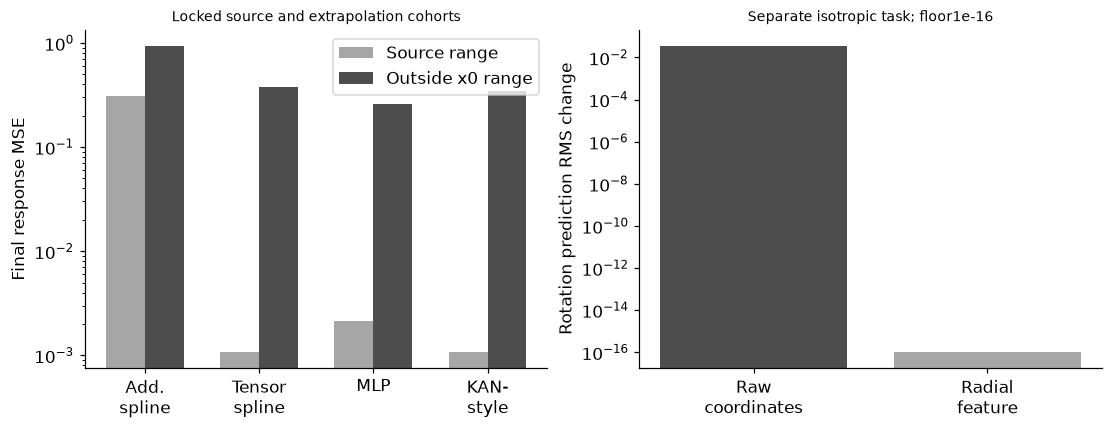

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.8));xx=np.arange(4)
axes[0].bar(xx-.17,[r['final_source_MSE'] for r in rows],.34,color='.65',label='Source range');axes[0].bar(xx+.17,[r['final_extrapolation_MSE'] for r in rows],.34,color='.3',label='Outside x0 range');axes[0].set(yscale='log',xticks=xx,xticklabels=['Add.\nspline','Tensor\nspline','MLP','KAN-\nstyle'],ylabel='Final response MSE',title='Locked source and extrapolation cohorts');axes[0].legend()
axes[1].bar([0,1],[max(r['rotation_prediction_RMS_difference'],1e-16) for r in geometry],color=['.3','.65']);axes[1].set(yscale='log',xticks=[0,1],xticklabels=['Raw\ncoordinates','Radial\nfeature'],ylabel='Rotation prediction RMS change',title='Separate isotropic task; floor1e-16');plt.show()
assert all(np.isfinite(r['final_extrapolation_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_114','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual differentiable cubic edge splines', 'SciPy basis and gradient checks', 'additive spline versus composed functions', 'locked extrapolation test', 'separate rotation-invariant task'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual differentiable cubic edge splines", "SciPy basis and gradient checks", "additive spline versus composed functions", "locked extrapolation test", "separate rotation-invariant task"], "elapsed_seconds": 2.367, "example_id": "code_114", "hardware": "Darwin arm64 CPU", "results": {"basis_SciPy_max_error": 1.1102230246251565e-16, "basis_count": 11, "candidates": [{"alpha": 0.01, "development_MSE": 0.29089192781154144, "model": "Additive spline"}, {"alpha": 1.0, "development_MSE": 0.278218923813495, "model": "Additive spline"}, {"alpha": 0.01, "development_MSE": 0.0011724709671943286, "model": "Tensor spline"}, {"alpha": 1.0, "development_MSE": 0.01184125788094893, "model": "Tensor spline"}, {"best_step": 400, "development_MSE": 0.002397650313599454, "model": "MLP", "rate": 0.005}, {"best_step": 400, "development_MSE": 0.002049115005245906, "model": "MLP", "rate": 0.01}, {"best_step": 400, "development_MSE": 0.0011381128193373885, "mo